# K-means Clustering

In [1]:
import matplotlib.cm as cm
import numpy as np
import pandas as pd
import plotly.io as pio

from IPython.display import display_html
from matplotlib import pyplot as plt
from plotly import express as px
from plotly import graph_objects as go
from plotly.subplots import make_subplots
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans,
)
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from src.data import (
    loader as data_loader,
)
from src.data import (
    sample as data_sample,
    display_ as data_display,
)

## Utils

In [2]:
pio.renderers.default = "png"

## Data

### Cercles

Read: cercles3.txt


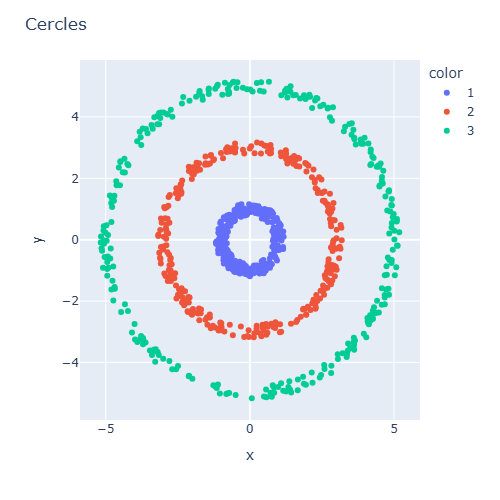

In [3]:
df_c = data_loader.load_cercles_ds()

# Plot data
fig = px.line(x=df_c["x1"], y=df_c["x2"], color=df_c["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="Cercles", width=500)

### Noeuds

Read: noeud.txt


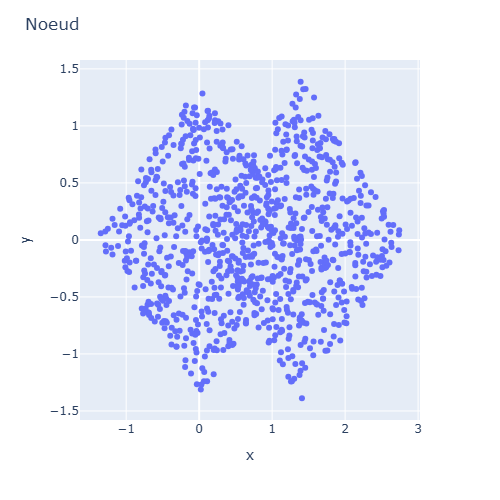

In [4]:
df_n = data_loader.load_noeud_ds()

# Plot data
fig = px.line(x=df_n["x1"], y=df_n["x2"])
fig.update_traces(mode="markers")
fig.update_layout(title="Noeud", width=500)

### Iris

Explained Variance Ratio: 97.77%


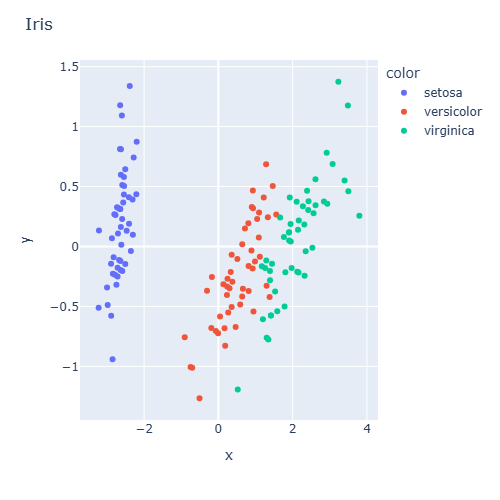

In [5]:
iris = datasets.load_iris()
assert iris is not None

X_raw = iris.data
iris_targets = iris.target
iris_target_names = iris.target_names

# PCA to keep first 2 principal components
pca = PCA(n_components=2)
pca.fit(X_raw)
total_explained_variance_ratio_ = np.sum(pca.explained_variance_ratio_)
assert total_explained_variance_ratio_ >= 0.95
print(f"Explained Variance Ratio: {total_explained_variance_ratio_:.2%}")

# Dimension reduced dataset
df_iris = pd.DataFrame(pca.transform(X_raw), columns=["x1", "x2"])
df_iris["y"] = iris_targets

# Plot data
fig = px.line(
    x=df_iris["x1"],
    y=df_iris["x2"],
    color=df_iris["y"].map(
        {i: iris_target_names[i] for i in range(len(iris_target_names))}
    ),
)
fig.update_traces(mode="markers")
fig.update_layout(title="Iris", width=500)

### Gaussian mixtures

#### With same covariance per class 

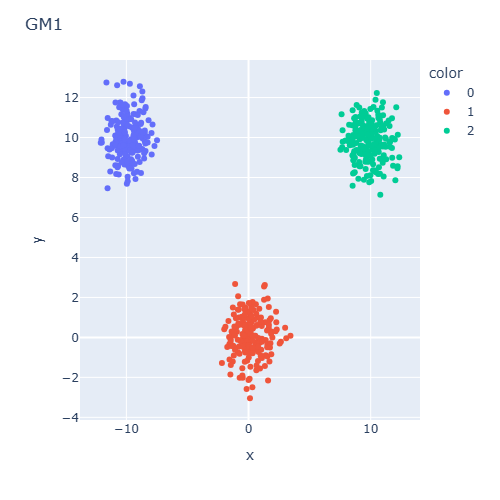

In [6]:
# Distributions Means
means = np.array([[-10, 10], [0, 0], [10, 10]])

# Distributions Covariances
cov = np.array([[1, 0], [0, 1]])
covs = [
    cov,
    cov,
    cov,
]

# Sample
df_gm1 = data_sample.generate_gaussian_mixture_sample(
    means=means, 
    covs=covs, 
    size=600, 
)

# Plot data
fig = px.line(x=df_gm1["x1"], y=df_gm1["x2"], color=df_gm1["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="GM1", width=500)

#### With different covariance per class 

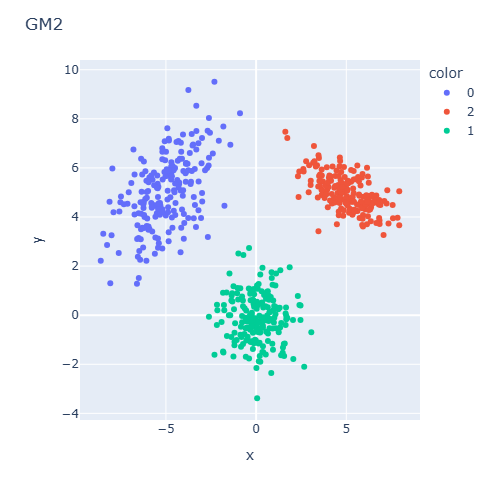

In [7]:
# Distributions Means
means = np.array([[-5, 5], [0, 0], [5, 5]])

# Distributions Covariances
covs = [
    np.array([[2, 1], [1, 2]]),
    np.array([[1, 0], [0, 1]]),
    np.array([[1.5, -0.5], [-0.5, 0.5]]),
]

# Sample
df_gm2 = data_sample.generate_gaussian_mixture_sample(
    means=means, 
    covs=covs, 
    size=600, 
)

# Plot data
fig = px.line(x=df_gm2["x1"], y=df_gm2["x2"], color=df_gm2["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="GM2", width=500)

### Consolidated datasets

In [8]:
dict_df_ds = {
    "cercles": df_c,
    "noeud": df_n,
    "iris": df_iris,
    "gm1": df_gm1,
    "gm2": df_gm2,
}
LIST_DS = [ds for ds in dict_df_ds]
N_DS = len(LIST_DS)
print(LIST_DS)

['cercles', 'noeud', 'iris', 'gm1', 'gm2']


## Train/Test Split

In [9]:
def get_train_test_split(
    df: pd.DataFrame,
) -> dict:

    X_raw = df[["x1", "x2"]]

    # Train-Test Split
    X, X_test = train_test_split(
        X_raw,
        test_size=0.25,
        random_state=0,  # reproducibility
        shuffle=True,
    )
    dict_split = {
        "train": {"X": X},
        "test": {"X": X_test},
    }
    return dict_split


DICT_DS_SPLIT = {n: get_train_test_split(df=dict_df_ds[n]) for n in dict_df_ds}

In [10]:
list_temp = [
    {
        "name": n,
        "split": t,
        "X": DICT_DS_SPLIT[n][t]["X"].shape,
        "pct": DICT_DS_SPLIT[n][t]["X"].shape[0] / dict_df_ds[n].shape[0],
    }
    for n in DICT_DS_SPLIT.keys()
    for t in DICT_DS_SPLIT[n]
]
pd.DataFrame(list_temp)

,name,split,X,pct
0,cercles,train,"(675, 2)",0.750000
1,cercles,test,"(225, 2)",0.250000
2,noeud,train,"(750, 2)",0.750000
3,noeud,test,"(250, 2)",0.250000
4,iris,train,"(112, 2)",0.746667
5,iris,test,"(38, 2)",0.253333
6,gm1,train,"(450, 2)",0.750000
7,gm1,test,"(150, 2)",0.250000
8,gm2,train,"(450, 2)",0.750000
9,gm2,test,"(150, 2)",0.250000


#

## K-means Clustering

cf Model definition in @notes.pdf

### Scikit-learn classes documentation

The documentation below was obtained using help(KMeans)

#### Classes

```
class KMeans(_BaseKMeans)
 |  KMeans(
 |      n_clusters=8,
 |      *,
 |      init='k-means++',
 |      n_init='auto',
 |      max_iter=300,
 |      tol=0.0001,
 |      verbose=0,
 |      random_state=None,
 |      copy_x=True,
 |      algorithm='lloyd'
 |  )
```

#### Parameters

```
 |  Parameters
 |  ----------
 |
 |  n_clusters : int, default=8
 |      The number of clusters to form as well as the number of
 |      centroids to generate.
 |
 |      For an example of how to choose an optimal value for `n_clusters` refer to
 |      :ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.
 |
 |  init : {'k-means++', 'random'}, callable or array-like of shape             (n_clusters, n_features), default='k-means++'
 |      Method for initialization:
 |
 |      * 'k-means++' : selects initial cluster centroids using sampling             based on an empirical probability distribution of the points'             contribution to the overall inertia. This technique speeds up             convergence. The algorithm implemented is "greedy k-means++". It             differs from the vanilla k-means++ by making several trials at             each sampling step and choosing the best centroid among them.
 |
 |      * 'random': choose `n_clusters` observations (rows) at random from         data for the initial centroids.
 |
 |      * If an array is passed, it should be of shape (n_clusters, n_features)        and gives the initial centers.
 |
 |      * If a callable is passed, it should take arguments X, n_clusters and a        random state and return an initialization.
 |
 |      For an example of how to use the different `init` strategies, see
 |      :ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.
 |
 |      For an evaluation of the impact of initialization, see the example
 |      :ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.
 |
 |  n_init : 'auto' or int, default='auto'
 |      Number of times the k-means algorithm is run with different centroid
 |      seeds. The final results is the best output of `n_init` consecutive runs
 |      in terms of inertia. Several runs are recommended for sparse
 |      high-dimensional problems (see :ref:`kmeans_sparse_high_dim`).
 |
 |      When `n_init='auto'`, the number of runs depends on the value of init:
 |      10 if using `init='random'` or `init` is a callable;
 |      1 if using `init='k-means++'` or `init` is an array-like.
 |
 |      .. versionadded:: 1.2
 |         Added 'auto' option for `n_init`.
 |
 |      .. versionchanged:: 1.4
 |         Default value for `n_init` changed to `'auto'`.
 |
 |  max_iter : int, default=300
 |      Maximum number of iterations of the k-means algorithm for a
 |      single run.
 |
 |  tol : float, default=1e-4
 |      Relative tolerance with regards to Frobenius norm of the difference
 |      in the cluster centers of two consecutive iterations to declare
 |      convergence.
 |
 |  verbose : int, default=0
 |      Verbosity mode.
 |
 |  random_state : int, RandomState instance or None, default=None
 |      Determines random number generation for centroid initialization. Use
 |      an int to make the randomness deterministic.
 |      See :term:`Glossary <random_state>`.
 |
 |  copy_x : bool, default=True
 |      When pre-computing distances it is more numerically accurate to center
 |      the data first. If copy_x is True (default), then the original data is
 |      not modified. If False, the original data is modified, and put back
 |      before the function returns, but small numerical differences may be
 |      introduced by subtracting and then adding the data mean. Note that if
 |      the original data is not C-contiguous, a copy will be made even if
 |      copy_x is False. If the original data is sparse, but not in CSR format,
 |      a copy will be made even if copy_x is False.
 |
 |  algorithm : {"lloyd", "elkan"}, default="lloyd"
 |      K-means algorithm to use. The classical EM-style algorithm is `"lloyd"`.
 |      The `"elkan"` variation can be more efficient on some datasets with
 |      well-defined clusters, by using the triangle inequality. However it's
 |      more memory intensive due to the allocation of an extra array of shape
 |      `(n_samples, n_clusters)`.
 |
 |      .. versionchanged:: 0.18
 |          Added Elkan algorithm
 |
 |      .. versionchanged:: 1.1
 |          Renamed "full" to "lloyd", and deprecated "auto" and "full".
 |          Changed "auto" to use "lloyd" instead of "elkan".
```

#### Attributes

```
Attributes
 |  ----------
 |  cluster_centers_ : ndarray of shape (n_clusters, n_features)
 |      Coordinates of cluster centers. If the algorithm stops before fully
 |      converging (see ``tol`` and ``max_iter``), these will not be
 |      consistent with ``labels_``.
 |
 |  labels_ : ndarray of shape (n_samples,)
 |      Labels of each point
 |
 |  inertia_ : float
 |      Sum of squared distances of samples to their closest cluster center,
 |      weighted by the sample weights if provided.
 |
 |  n_iter_ : int
 |      Number of iterations run.
 |
 |  n_features_in_ : int
 |      Number of features seen during :term:`fit`.
 |
 |      .. versionadded:: 0.24
 |
 |  feature_names_in_ : ndarray of shape (`n_features_in_`,)
 |      Names of features seen during :term:`fit`. Defined only when `X`
 |      has feature names that are all strings.
```

### Classifiers Instance

## Fit Models

- n_clusters study
- init & n_init study

In [ ]:
def fit_models(
    dict_ds_split: dict,
    dict_clf_params: dict,
):
    dict_clf = {}
    dict_data_pred = {}
    for name_ds in dict_ds_split:
        _dict_ds = dict_ds_split[name_ds]
        dict_data_pred[name_ds] = {}
        dict_clf[name_ds] = {}
        for _clf_n, _clf_kwargs in dict_clf_params.items():
            _clf_i = KMeans(**_clf_kwargs)
            print(f"{name_ds} - Fit n_clsuters={_clf_kwargs['n_clusters']}")
            
            dict_data_pred[name_ds][_clf_n] = {}
            
            # Fit models on training set
            _clf_i.fit(_dict_ds["train"]["X"])
            dict_clf[name_ds][_clf_n] = _clf_i
            inertia_ = _clf_i.inertia_

            for _split in _dict_ds:
                
                # Models prediction on both sets
                _clusters_predicted = _clf_i.predict(_dict_ds[_split]["X"])

                # Silhouette score
                slt_score = silhouette_score(X=_dict_ds[_split]["X"], labels=_clusters_predicted)
                slt_samples = silhouette_samples(X=_dict_ds[_split]["X"], labels=_clusters_predicted)

                # Data
                dict_data_pred[name_ds][_clf_n][_split] = {
                    "n_clusters": _clf_kwargs['n_clusters'],
                    "predicted": _clf_i.predict(_dict_ds[_split]["X"]),
                    "inertia": inertia_ if _split == "train" else np.nan,
                    "avg_slh_score": slt_score,
                    "slh_values": slt_samples,
                    "classes": list(set(_clusters_predicted)),
                    "n_iter_": _clf_i.n_iter_, 
                }
        print('+' * 50)

    return dict_data_pred, dict_clf

## Selecting the best number of clusters

In [12]:
LIST_N_CLUSTERS = list(range(2, 11))
DICT_CLS_PARAMS = {
    f'kmeans_{n}' : {'n_clusters': n, 'init': 'k-means++', 'n_init': 1, 'random_state': 1, 'algorithm': 'lloyd'} 
    for n in LIST_N_CLUSTERS
}
LIST_SPLITS = ["train", "test"]
DICT_CLF = {}
DICT_DATA_PRED, DICT_CLF = fit_models(dict_ds_split=DICT_DS_SPLIT, dict_clf_params=DICT_CLS_PARAMS)
DICT_CLS_PARAMS.keys()

cercles - Fit n_clsuters=2
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=4
cercles - Fit n_clsuters=5
cercles - Fit n_clsuters=6
cercles - Fit n_clsuters=7
cercles - Fit n_clsuters=8
cercles - Fit n_clsuters=9
cercles - Fit n_clsuters=10
++++++++++++++++++++++++++++++++++++++++++++++++++
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=3
noeud - Fit n_clsuters=4
noeud - Fit n_clsuters=5
noeud - Fit n_clsuters=6
noeud - Fit n_clsuters=7
noeud - Fit n_clsuters=8
noeud - Fit n_clsuters=9
noeud - Fit n_clsuters=10
++++++++++++++++++++++++++++++++++++++++++++++++++
iris - Fit n_clsuters=2
iris - Fit n_clsuters=3
iris - Fit n_clsuters=4
iris - Fit n_clsuters=5
iris - Fit n_clsuters=6
iris - Fit n_clsuters=7
iris - Fit n_clsuters=8
iris - Fit n_clsuters=9
iris - Fit n_clsuters=10
++++++++++++++++++++++++++++++++++++++++++++++++++
gm1 - Fit n_clsuters=2
gm1 - Fit n_clsuters=3
gm1 - Fit n_clsuters=4
gm1 - Fit n_clsuters=5
gm1 - Fit n_clsuters=6
gm1 - Fit n_clsuters=7
gm1 - Fit n_clsuters=8

dict_keys(['kmeans_2', 'kmeans_3', 'kmeans_4', 'kmeans_5', 'kmeans_6', 'kmeans_7', 'kmeans_8', 'kmeans_9', 'kmeans_10'])

### Inertia & Avg Silhouette Score

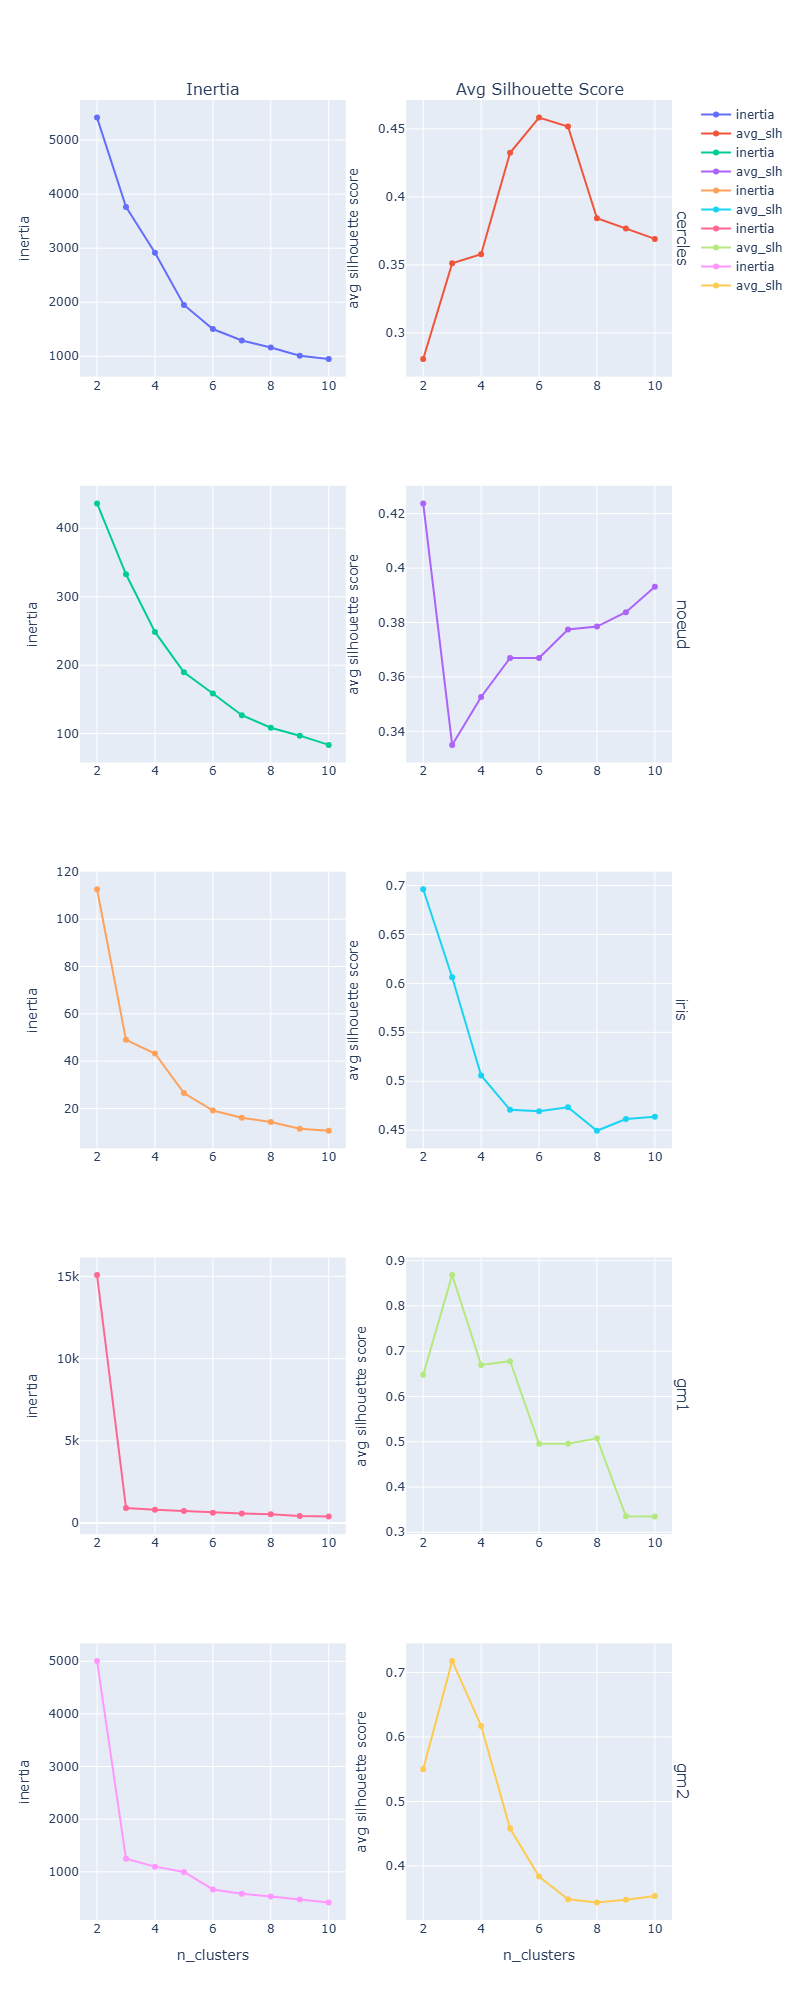

In [30]:
# list_ds_plot = ["gm1"]
list_ds_plot = [ds for ds in DICT_DS_SPLIT]

dict_data_plot = {ds: DICT_DS_SPLIT[ds] for ds in list_ds_plot}
split_plot = 'train'

nrows = len(list_ds_plot)
ncols = 2
fig = make_subplots(
    rows=nrows, 
    cols=ncols,
    row_titles=[ds for ds in dict_data_plot],
    column_titles=["Inertia", "Avg Silhouette Score"],
)

for _idx_row, name_ds in enumerate(dict_data_plot):
        _n_clusters = [DICT_DATA_PRED[name_ds][_clf_n][split_plot]['n_clusters'] for _clf_n in DICT_CLS_PARAMS]
        _inertia = [DICT_DATA_PRED[name_ds][_clf_n][split_plot]['inertia'] for _clf_n in DICT_CLS_PARAMS]
        _avg_slh_score = [DICT_DATA_PRED[name_ds][_clf_n][split_plot]['avg_slh_score'] for _clf_n in DICT_CLS_PARAMS]
        
        fig.add_trace(go.Scatter(x=_n_clusters, y=_inertia, name='inertia'), row=_idx_row + 1, col=1)
        fig.add_trace(go.Scatter(x=_n_clusters, y=_avg_slh_score, name='avg_slh'), row=_idx_row + 1, col=2)

        fig.update_yaxes(title="inertia", row=_idx_row + 1, col=1)
        fig.update_yaxes(title="avg silhouette score", row=_idx_row + 1, col=2)

fig.update_xaxes(title='n_clusters', row=nrows, col=1)
fig.update_xaxes(title='n_clusters', row=nrows, col=2)        
fig.update_layout(width=400 * ncols, height=400 * nrows)
fig.show()

Choosing the right number of clusters:

- GM1 & GM2:

    From n_clusters = 3, the inertia does not decrease much hence one can choose the optimal value $\text{n\_clusters} = 3$   

    The avg silhouette score is maximal for n_clusters = 3. Which is coherent with the expected result 

-  Iris:

    Without the knowledge of the iris types, the inertia graph could make one choose even $\text{n\_clusters} \gt 5$ 
    
    However the low silhouette score for $\text{n\_clusters} \gt 3$ indicates that the right number of clusters is not more than $3$

    Without any knowledge about the fact that there are only 3 types of iris, these graphs alone could not be enough to determinethe right number of clusters.
    
    For We will keep $\text{n\_clusters} = 3$

- Cercles:

    This dataset has 3 clusters and all of them have the same centroid. Hence it was expected that the k-means algorithm performs poorly

    cf low silhouette score



This illustrates the fact knowledge about the dataset, inertia and avg silhouette score are complementary to determine the right number of clusters.

In [28]:
DICT_N_CLUSTERS = {
    'cercles': 3,
    'noeud': 2,
    'iris': 3,
    'gm1': 3,
    'gm2': 3,
}
pd.DataFrame([DICT_N_CLUSTERS], index=['n_clusters'])

,cercles,noeud,iris,gm1,gm2
n_clusters,3,2,3,3,3


### Results

#### Predicted Clusters

In [15]:
def plot_predicted_clusters(
    list_ds: list | None,
    split: str,
):
    list_ds = list_ds or [ds for ds in DICT_DATA_PRED]
    dict_data = {
        ds: {clf_name: DICT_DATA_PRED[ds] for clf_name in [f'kmeans_{DICT_N_CLUSTERS[ds]}']} 
        for ds in list_ds
    }

    # Figure
    nrows = len(dict_data)
    ncols = 2
    row_titles = tuple([ds.title() for ds in list_ds])
    column_titles = tuple(["Clusters", "Silhouette Score Per Cluster"])

    fig = make_subplots(
        rows=nrows,
        cols=ncols,
        row_titles=row_titles,
        column_titles=column_titles,
    )

    # Predicted Clusters
    for _idx_row, ds in enumerate(dict_data):

        # Features
        Xs = DICT_DS_SPLIT[ds][split]["X"]

        # Classes
        _n_clusters = DICT_N_CLUSTERS[ds]
        _clf_name = f'kmeans_{_n_clusters}'
        ys_pred = DICT_DATA_PRED[ds][_clf_name][split]["predicted"]
        assert Xs.shape[0] == ys_pred.shape[0]

        # Cluster colors (shared between scatter and box traces)
        slh_values = DICT_DATA_PRED[ds][_clf_name][split]["slh_values"]
        classes = DICT_DATA_PRED[ds][_clf_name][split]["classes"]
        palette = px.colors.qualitative.Plotly
        cluster_colors = {
            _class: palette[_idx % len(palette)]
            for _idx, _class in enumerate(classes)
        }
        point_colors = [cluster_colors[_class] for _class in ys_pred]

        # Predicted Clusters
        trace_pred = go.Scatter(
            x=Xs["x1"],
            y=Xs["x2"],
            mode="markers",
            marker=dict(color=point_colors),
            name="predicted_target",
        )
        fig.add_trace(trace_pred, row=_idx_row + 1, col=1)

        # Avg Silhouette Score per class
        for _class in classes: 
            _trace_box = go.Box(
                y=slh_values[ys_pred == _class], 
                name=f"Cluster {_class}", 
                marker=dict(color=cluster_colors[_class]),
                line=dict(color=cluster_colors[_class]),
            )
            fig.add_trace(_trace_box, row=_idx_row + 1, col=2)

        fig.update_xaxes(title="x1", row=_idx_row + 1, col=1)
        fig.update_yaxes(title="x2", row=_idx_row + 1, col=1)
        fig.update_yaxes(title="silhouette score", row=_idx_row + 1, col=2)

    fig.update_layout(title=f"{split.title()} Set, Predicted Clusters")
    fig.update_layout(width=500 * ncols, height=500 * nrows)
    return fig

### Train Set

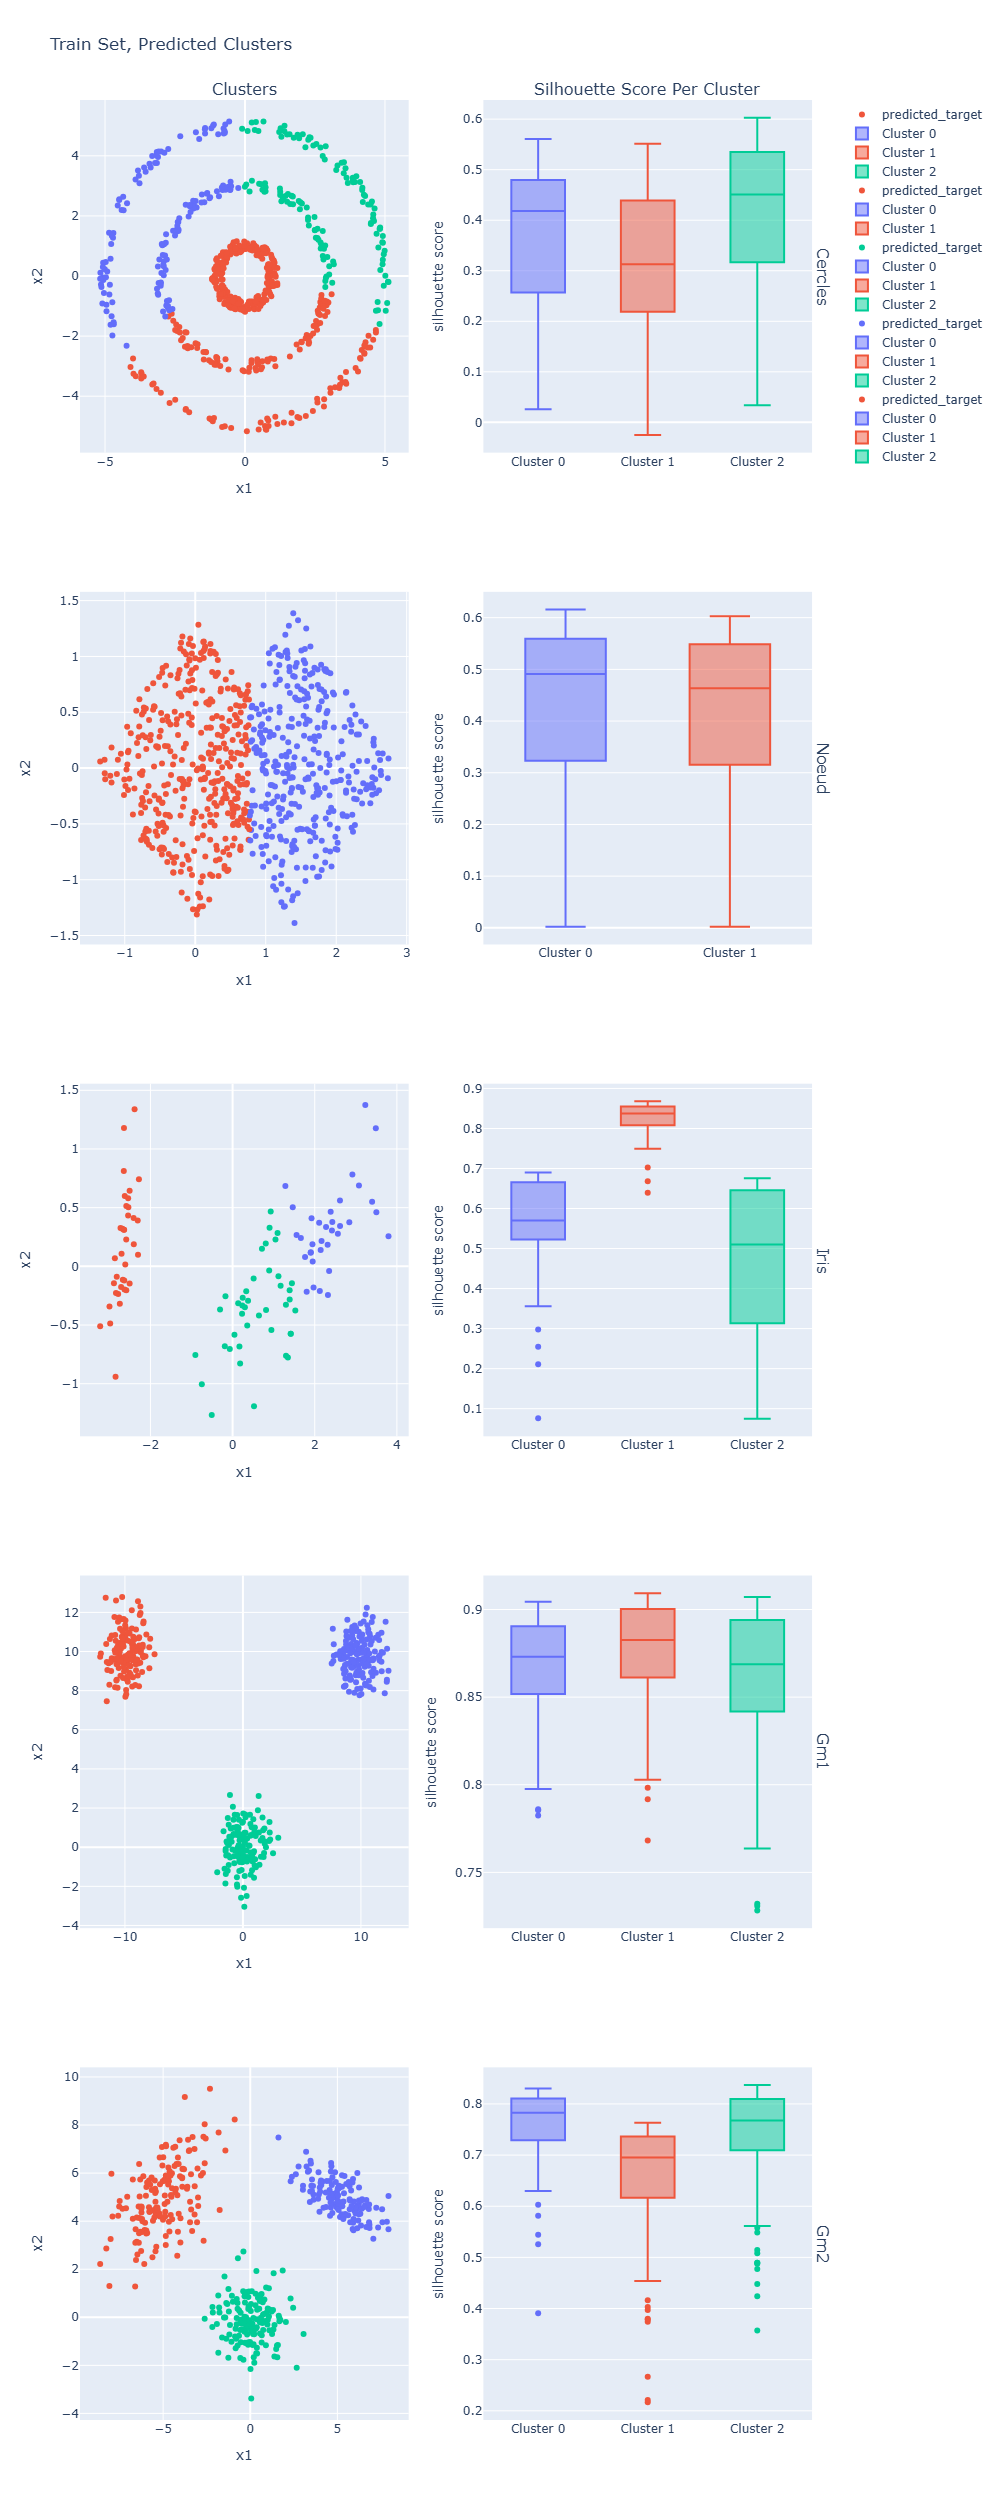

In [21]:
fig = plot_predicted_clusters(list_ds=None, split="train")
fig.show()

### Test Set

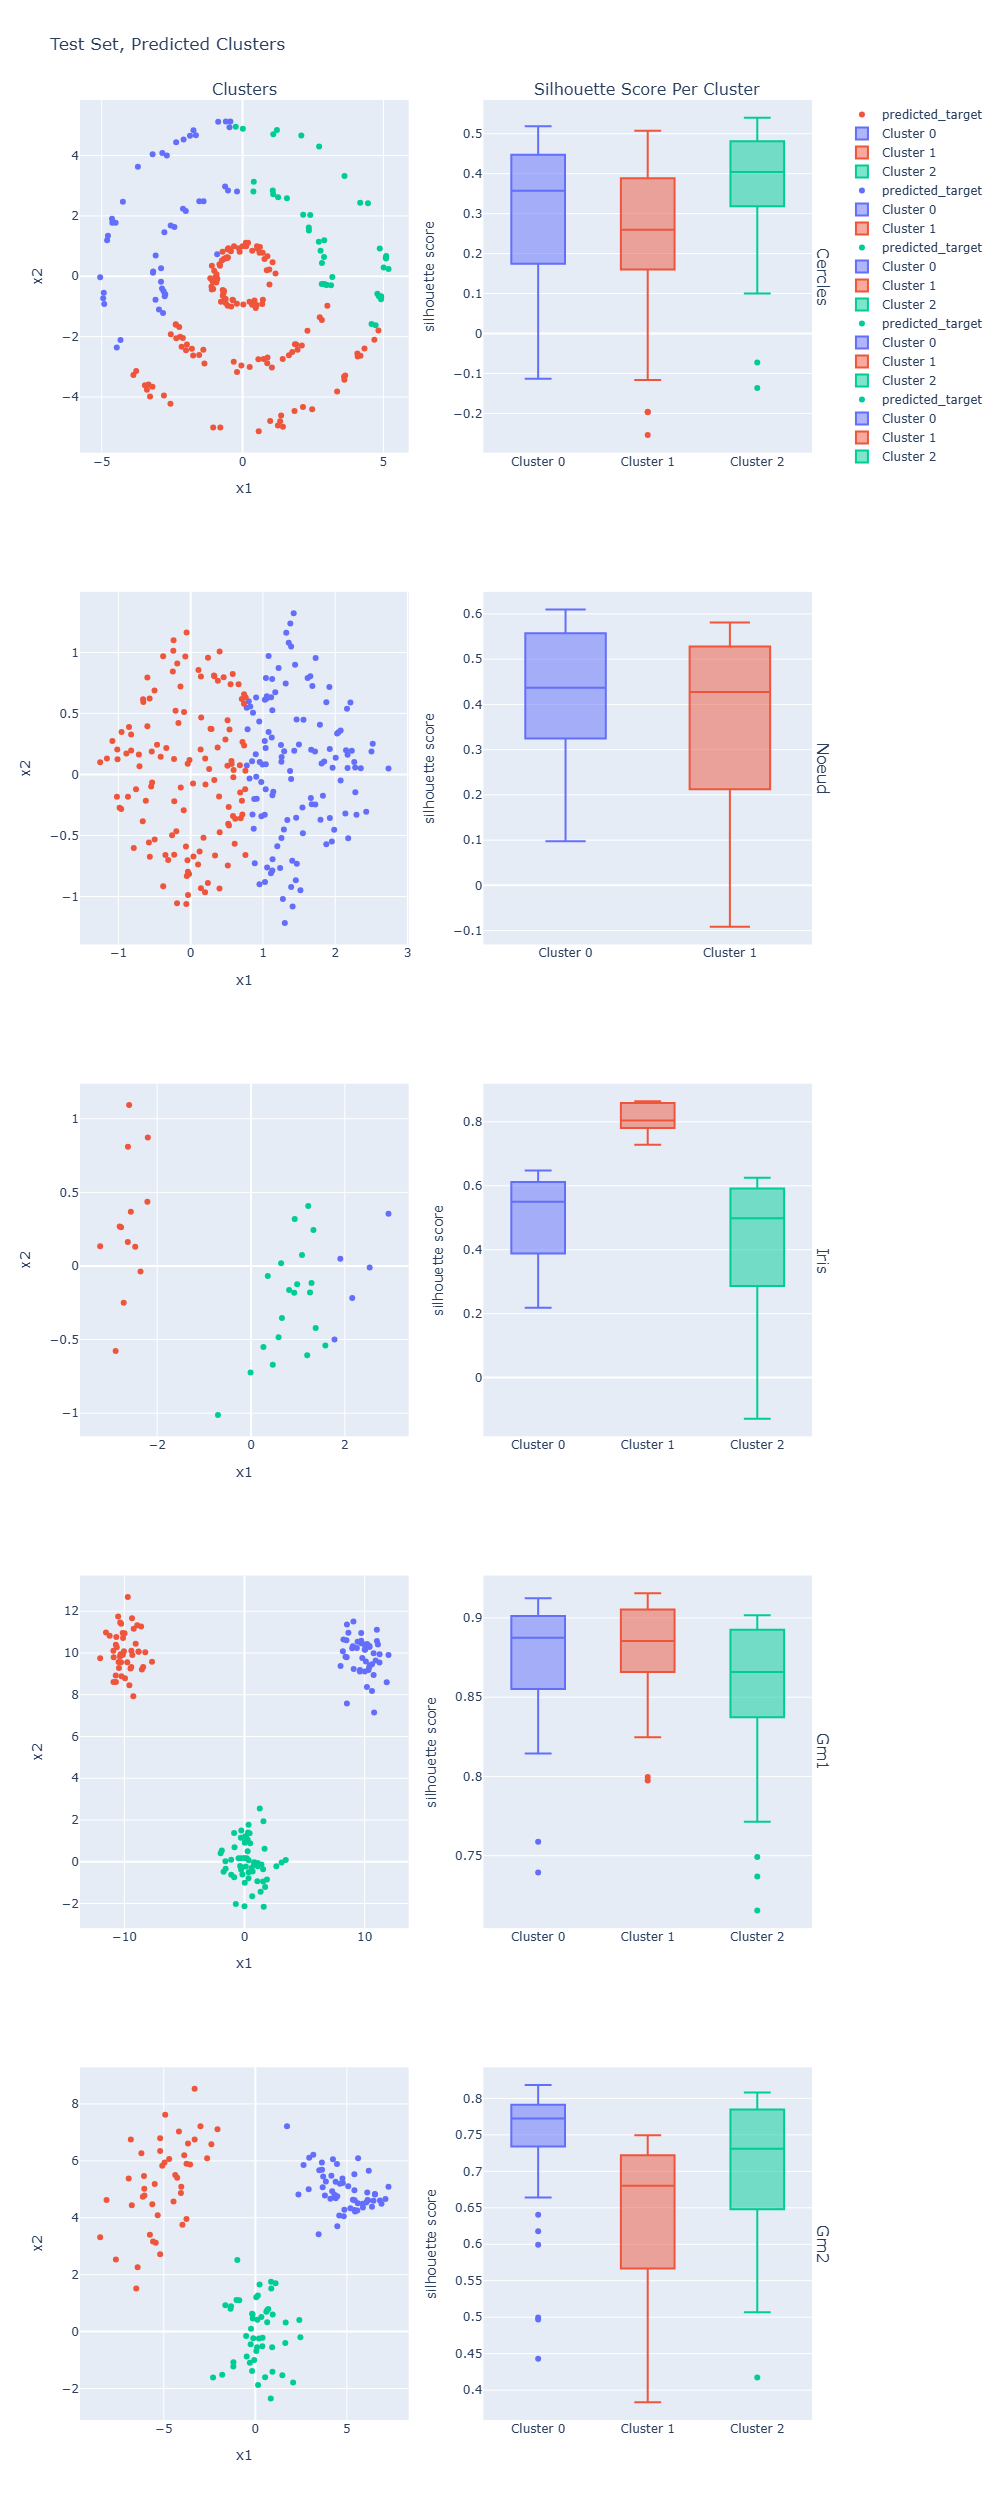

In [26]:
fig = plot_predicted_clusters(list_ds=None, split="test")
fig.show()

## Impact on initialization

In [24]:
n_init_range = np.array([1, 2, 3, 4, 5, 10, 15, 20])

DICT_DATA_PRED_2 = {}
DICT_CLF_2 = {}
LIST_INIT = ['random', 'k-means++']
for _ds in DICT_N_CLUSTERS:
    _n_clusters = DICT_N_CLUSTERS[_ds]
    _dict_clf_params = {
        f'{i}_{n_init}' : {'n_clusters': _n_clusters, 'init': i, 'n_init': n_init, 'random_state': 1, 'algorithm': 'lloyd'} 
        for i in LIST_INIT
        for n_init in n_init_range
    }
    
    _dict_data_pred, _dict_clf = fit_models(
        dict_ds_split={k: v for k, v in DICT_DS_SPLIT.items() if k == _ds}, 
        dict_clf_params=_dict_clf_params,
    )
    DICT_DATA_PRED_2 = {**DICT_DATA_PRED_2, **_dict_data_pred}
    DICT_CLF_2 = {**DICT_CLF_2, **_dict_clf}

cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
cercles - Fit n_clsuters=3
++++++++++++++++++++++++++++++++++++++++++++++++++
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
noeud - Fit n_clsuters=2
++++++++++++++++++++++++++++++++++++++++++++++++++
iris - Fit n_clsuters=3
iris - Fit n_clsuters=3
iris - Fit n_clsut

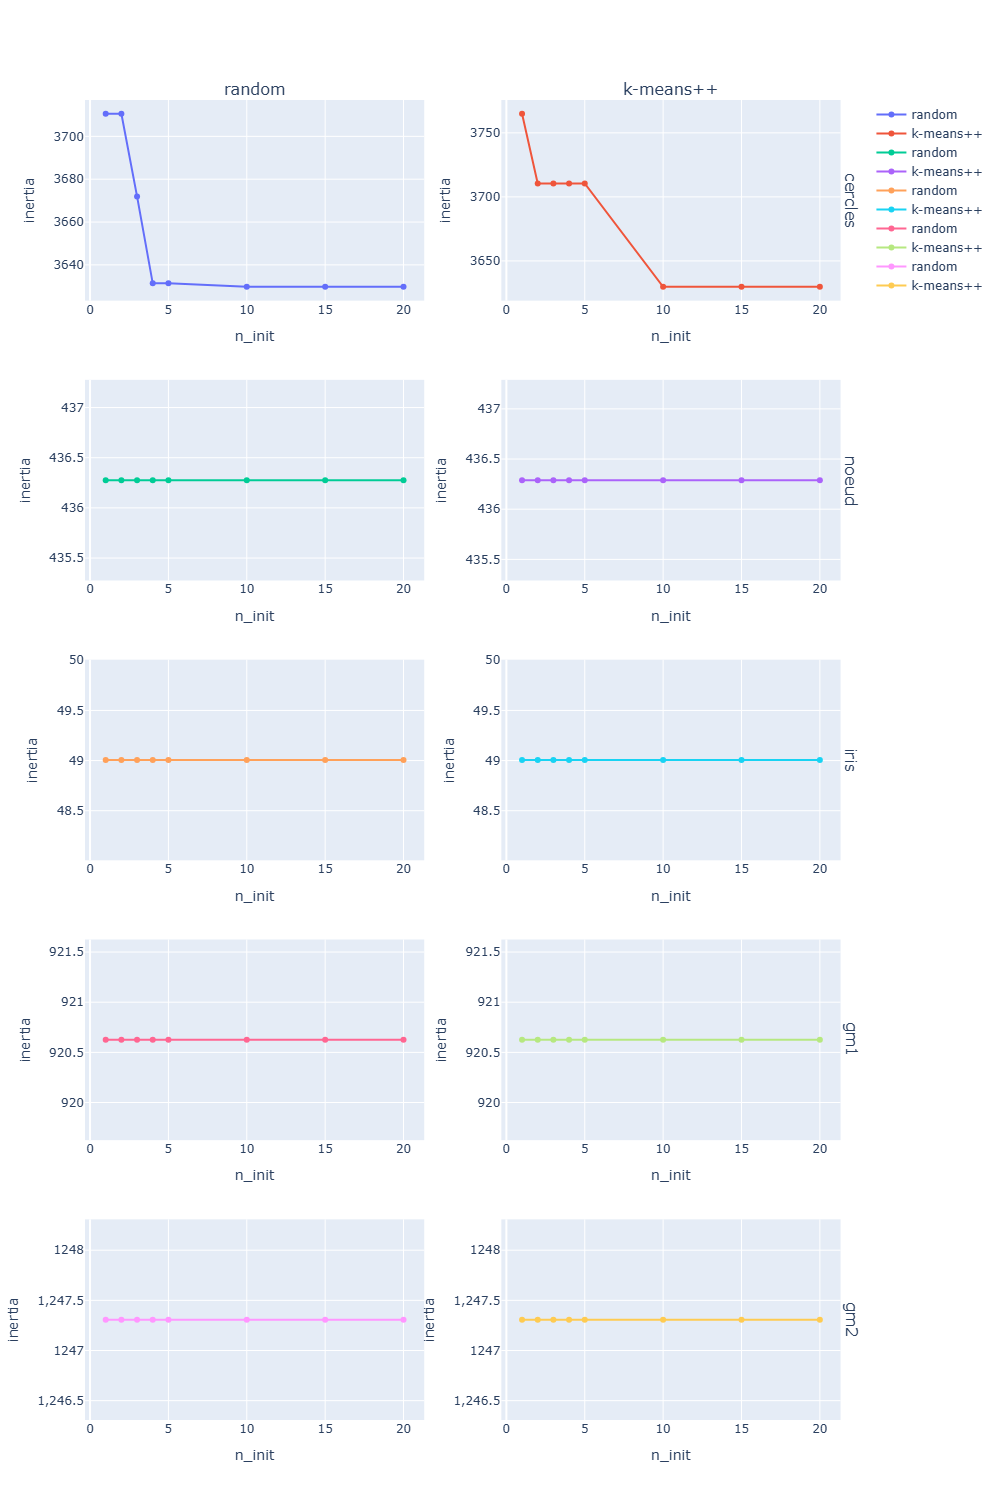

In [22]:
nrows = N_DS
ncols = 2
fig = make_subplots(
    rows=nrows,
    cols=ncols,
    row_titles=[d for d in DICT_DATA_PRED_2],
    column_titles=LIST_INIT,
)

split_dbg = "train"

for _idx_row, _name_ds in enumerate(DICT_DATA_PRED_2):
    for _idx_col, init_method in enumerate(LIST_INIT):
        ys_dbg = [DICT_DATA_PRED_2[_name_ds][f'{init_method}_{n}'][split_dbg]["inertia"] for n in n_init_range]
        trace = go.Scatter(x=n_init_range, y=ys_dbg, name=init_method)
        fig.add_trace(trace=trace, row=_idx_row + 1, col=_idx_col + 1)

fig.update_xaxes(title="n_init")
fig.update_yaxes(title="inertia")
fig.update_layout(height=300 * nrows, width=500 * ncols)
fig.show()

One can notice that using init='k-means++' in almost all the previous examples the algorithm needs less initializations to reach the optimum inertia  